In [ ]:
!pip install pandas numpy matplotlib seaborn textblob vaderSentiment plotly

In [2]:
!pip install pandas numpy matplotlib seaborn textblob vaderSentiment plotly

Defaulting to user installation because normal site-packages is not writeable
  Using cached textblob-0.20.1-py3-none-any.whl.metadata (4.0 kB)
  Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl.metadata (572 bytes)
  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
Using cached textblob-0.20.1-py3-none-any.whl (624 kB)
Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl (125 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)

   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [nltk]
   ------------- -------------------------- 1/3 [n

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
os.makedirs("Outputs", exist_ok=True)
os.makedirs("Screenshots", exist_ok=True)

print("Project folders are ready!")

Project folders are ready!


In [5]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("Datasets loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'googleplaystore.csv'

In [6]:
import os

print("Current Notebook Location:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current Notebook Location:
C:\Users\sanaa\OneDrive\Desktop\OIBSIP\DataAnalytics-Level2-Task4-PlayStoreAnalysis

Files available in this folder:
['.ipynb_checkpoints', 'archive (3)', 'OIBSIP_Level2_Task4_PlayStore_Analysis.ipynb', 'Outputs', 'Screenshots']


In [7]:
import os

print(os.listdir("archive (3)"))

['googleplaystore.csv', 'googleplaystore_user_reviews.csv', 'license.txt']


In [8]:
apps = pd.read_csv("archive (3)/googleplaystore.csv")
reviews = pd.read_csv("archive (3)/googleplaystore_user_reviews.csv")

print("Both datasets loaded successfully!")

Both datasets loaded successfully!


In [9]:
print("Apps Dataset:", apps.shape)
print("Reviews Dataset:", reviews.shape)

display(apps.head())
display(reviews.head())

Apps Dataset: (10841, 13)
Reviews Dataset: (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [10]:
print("Apps Dataset Shape:", apps.shape)
print("Reviews Dataset Shape:", reviews.shape)

Apps Dataset Shape: (10841, 13)
Reviews Dataset Shape: (64295, 5)


In [11]:
print("GOOGLE PLAY STORE APPS")
display(apps.head())

print("\nUSER REVIEWS")
display(reviews.head())

GOOGLE PLAY STORE APPS


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



USER REVIEWS


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [12]:
print("APPS DATASET INFORMATION")
apps.info()

print("\nREVIEWS DATASET INFORMATION")
reviews.info()

APPS DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB

REVIEWS DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                

In [13]:
print("Missing Values in Apps Dataset:")
print(apps.isnull().sum())

print("\nMissing Values in Reviews Dataset:")
print(reviews.isnull().sum())

Missing Values in Apps Dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Missing Values in Reviews Dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


In [14]:
print("Duplicate Apps:", apps.duplicated().sum())
print("Duplicate Reviews:", reviews.duplicated().sum())

Duplicate Apps: 483
Duplicate Reviews: 33616


In [15]:
print("Apps Columns:")
print(apps.columns.tolist())

print("\nReviews Columns:")
print(reviews.columns.tolist())

Apps Columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Reviews Columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [16]:
apps = apps.drop_duplicates()
reviews = reviews.drop_duplicates()

print("Duplicates removed successfully!")
print("Apps Shape:", apps.shape)
print("Reviews Shape:", reviews.shape)

Duplicates removed successfully!
Apps Shape: (10358, 13)
Reviews Shape: (30679, 5)


In [17]:
print("APPS DATASET MISSING VALUES (%)")
print((apps.isnull().mean() * 100).round(2))

print("\nREVIEWS DATASET MISSING VALUES (%)")
print((reviews.isnull().mean() * 100).round(2))

APPS DATASET MISSING VALUES (%)
App                0.00
Category           0.00
Rating            14.14
Reviews            0.00
Size               0.00
Installs           0.00
Type               0.01
Price              0.00
Content Rating     0.01
Genres             0.00
Last Updated       0.00
Current Ver        0.08
Android Ver        0.03
dtype: float64

REVIEWS DATASET MISSING VALUES (%)
App                       0.00
Translated_Review         3.22
Sentiment                 3.20
Sentiment_Polarity        3.20
Sentiment_Subjectivity    3.20
dtype: float64


In [18]:
apps = apps.dropna(subset=["App", "Category", "Rating"])

print("Missing values in important columns handled!")
print("Updated Apps Shape:", apps.shape)

Missing values in important columns handled!
Updated Apps Shape: (8893, 13)


In [19]:
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")

apps = apps.dropna(subset=["Rating"])

print("Rating converted successfully!")

Rating converted successfully!


In [20]:
apps["Installs"] = (
    apps["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

apps["Installs"] = pd.to_numeric(apps["Installs"], errors="coerce")

print("Installs converted successfully!")

Installs converted successfully!


In [21]:
apps["Price"] = (
    apps["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

apps["Price"] = pd.to_numeric(apps["Price"], errors="coerce")

apps["Price"] = apps["Price"].fillna(0)

print("Price converted successfully!")

Price converted successfully!


In [22]:
def convert_size(size):
    size = str(size).strip()

    if size.endswith("M"):
        return float(size[:-1])

    elif size.endswith("k"):
        return float(size[:-1]) / 1024

    else:
        return np.nan

apps["Size"] = apps["Size"].apply(convert_size)

print("Size converted into MB!")

Size converted into MB!


In [23]:
print(apps[["App", "Rating", "Size", "Installs", "Price"]].head(10))

print("\nData Types:")
print(apps[["Rating", "Size", "Installs", "Price"]].dtypes)

                                                 App  Rating  Size  \
0     Photo Editor & Candy Camera & Grid & ScrapBook     4.1  19.0   
1                                Coloring book moana     3.9  14.0   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...     4.7   8.7   
3                              Sketch - Draw & Paint     4.5  25.0   
4              Pixel Draw - Number Art Coloring Book     4.3   2.8   
5                         Paper flowers instructions     4.4   5.6   
6            Smoke Effect Photo Maker - Smoke Editor     3.8  19.0   
7                                   Infinite Painter     4.1  29.0   
8                               Garden Coloring Book     4.4  33.0   
9                      Kids Paint Free - Drawing Fun     4.7   3.1   

     Installs  Price  
0     10000.0    0.0  
1    500000.0    0.0  
2   5000000.0    0.0  
3  50000000.0    0.0  
4    100000.0    0.0  
5     50000.0    0.0  
6     50000.0    0.0  
7   1000000.0    0.0  
8   1000000.0    0.0  

In [24]:
category_counts = apps["Category"].value_counts()

print("Number of Apps in Each Category:")
display(category_counts)

Number of Apps in Each Category:


Category
FAMILY                 1718
GAME                   1074
TOOLS                   734
PRODUCTIVITY            334
FINANCE                 317
PERSONALIZATION         310
COMMUNICATION           307
LIFESTYLE               305
PHOTOGRAPHY             304
MEDICAL                 302
SPORTS                  286
BUSINESS                270
HEALTH_AND_FITNESS      262
SOCIAL                  244
NEWS_AND_MAGAZINES      214
TRAVEL_AND_LOCAL        205
SHOPPING                202
BOOKS_AND_REFERENCE     177
VIDEO_PLAYERS           160
DATING                  159
EDUCATION               129
MAPS_AND_NAVIGATION     124
ENTERTAINMENT           111
FOOD_AND_DRINK          106
WEATHER                  75
AUTO_AND_VEHICLES        73
HOUSE_AND_HOME           68
LIBRARIES_AND_DEMO       65
ART_AND_DESIGN           62
COMICS                   58
PARENTING                50
EVENTS                   45
BEAUTY                   42
1.9                       1
Name: count, dtype: int64

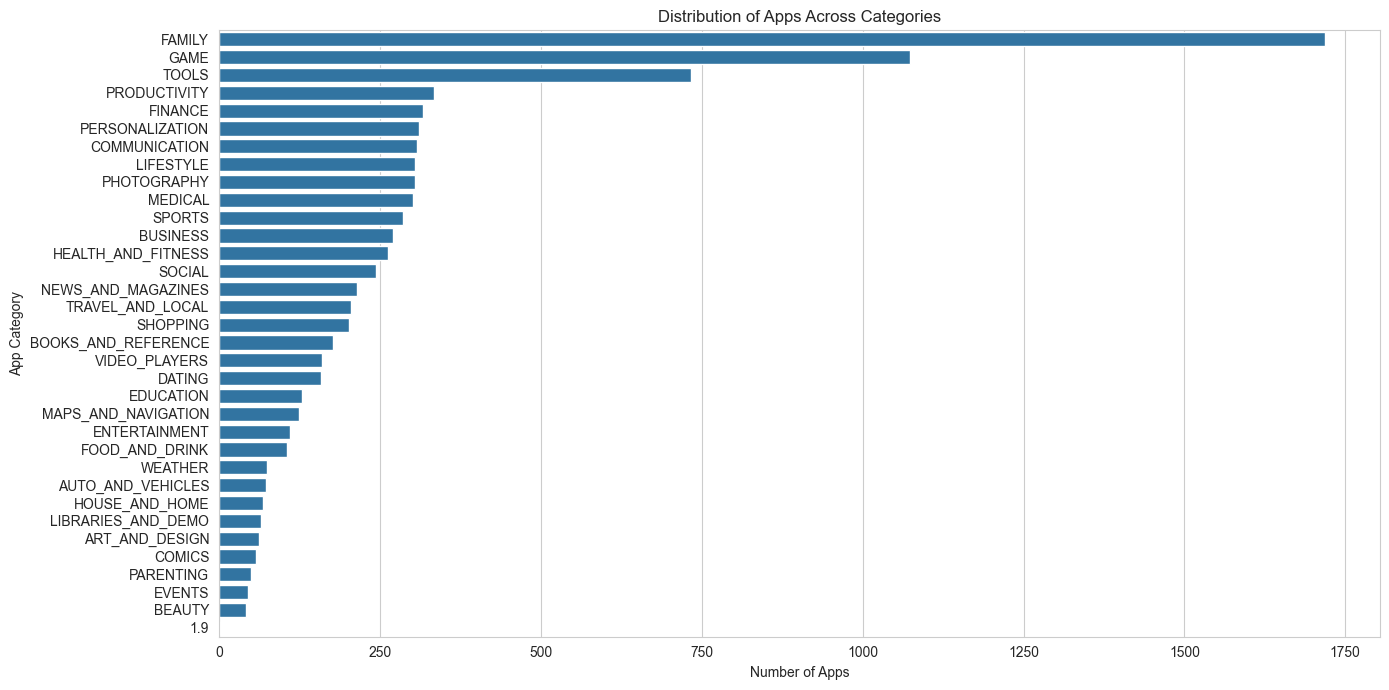

In [25]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=apps,
    y="Category",
    order=apps["Category"].value_counts().index
)

plt.title("Distribution of Apps Across Categories")
plt.xlabel("Number of Apps")
plt.ylabel("App Category")
plt.tight_layout()

plt.savefig("Screenshots/category_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

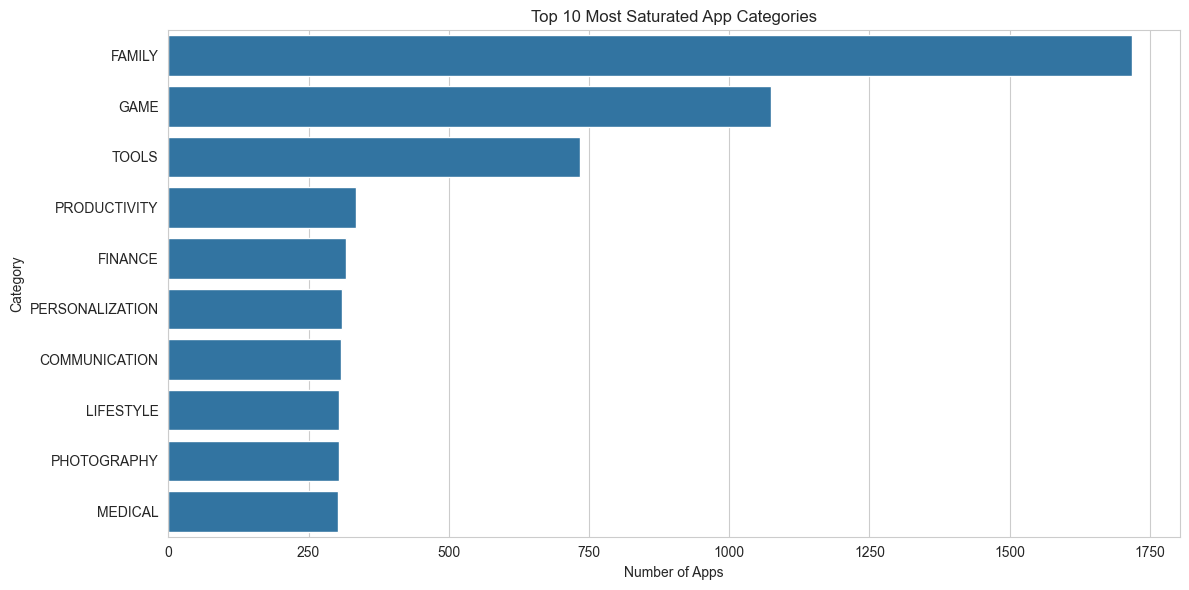

In [26]:
top_categories = category_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Most Saturated App Categories")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig("Screenshots/top_10_categories.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
print("TOP 5 CATEGORIES:")
display(category_counts.head(5))

print("\nBOTTOM 5 CATEGORIES:")
display(category_counts.tail(5))

TOP 5 CATEGORIES:


Category
FAMILY          1718
GAME            1074
TOOLS            734
PRODUCTIVITY     334
FINANCE          317
Name: count, dtype: int64


BOTTOM 5 CATEGORIES:


Category
COMICS       58
PARENTING    50
EVENTS       45
BEAUTY       42
1.9           1
Name: count, dtype: int64

## Category Analysis

The Google Play Store contains apps from different categories.

The category distribution chart shows the number of apps available in each category.

Categories with a higher number of apps are considered more saturated because they have greater competition.

This analysis helps developers identify crowded categories and explore opportunities in less crowded categories.

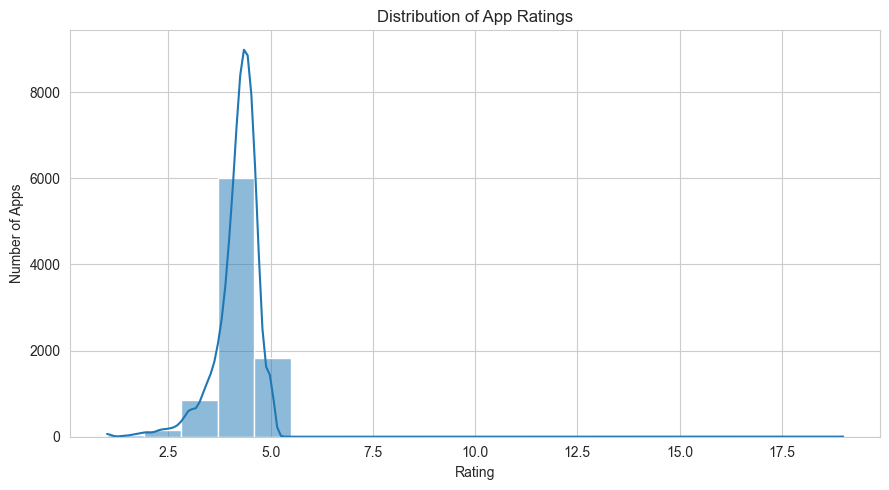

In [28]:
plt.figure(figsize=(9, 5))

sns.histplot(apps["Rating"], bins=20, kde=True)

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()

plt.savefig("Screenshots/rating_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
average_rating = apps["Rating"].mean()

print("Average Google Play Store Rating:", round(average_rating, 2))

Average Google Play Store Rating: 4.19


In [30]:
category_ratings = (
    apps.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Rating by Category:")
display(category_ratings.round(2))

Average Rating by Category:


Category
1.9                    19.00
EVENTS                  4.44
EDUCATION               4.38
ART_AND_DESIGN          4.36
BOOKS_AND_REFERENCE     4.35
PERSONALIZATION         4.33
PARENTING               4.30
GAME                    4.28
BEAUTY                  4.28
HEALTH_AND_FITNESS      4.26
SOCIAL                  4.25
SHOPPING                4.25
WEATHER                 4.24
SPORTS                  4.23
PRODUCTIVITY            4.20
FAMILY                  4.19
AUTO_AND_VEHICLES       4.19
PHOTOGRAPHY             4.18
MEDICAL                 4.18
LIBRARIES_AND_DEMO      4.18
HOUSE_AND_HOME          4.16
FOOD_AND_DRINK          4.16
COMICS                  4.16
COMMUNICATION           4.15
ENTERTAINMENT           4.14
NEWS_AND_MAGAZINES      4.13
FINANCE                 4.13
BUSINESS                4.10
LIFESTYLE               4.10
TRAVEL_AND_LOCAL        4.09
VIDEO_PLAYERS           4.06
MAPS_AND_NAVIGATION     4.05
TOOLS                   4.05
DATING                  3.97
Name:

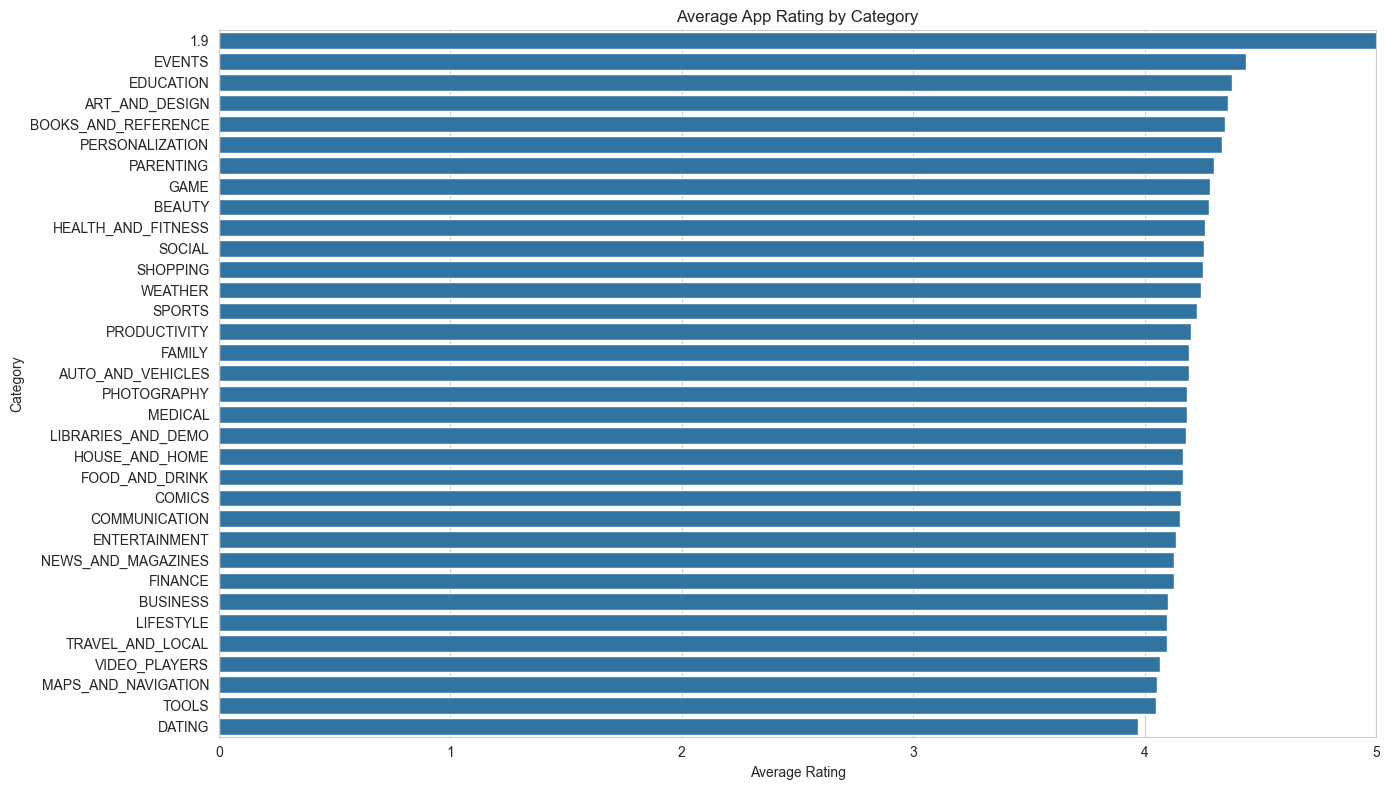

In [31]:
plt.figure(figsize=(14, 8))

sns.barplot(
    x=category_ratings.values,
    y=category_ratings.index
)

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()

plt.savefig("Screenshots/average_rating_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
print("TOP 5 HIGHEST RATED CATEGORIES:")
display(category_ratings.head(5).round(2))

print("\nBOTTOM 5 LOWEST RATED CATEGORIES:")
display(category_ratings.tail(5).round(2))

TOP 5 HIGHEST RATED CATEGORIES:


Category
1.9                    19.00
EVENTS                  4.44
EDUCATION               4.38
ART_AND_DESIGN          4.36
BOOKS_AND_REFERENCE     4.35
Name: Rating, dtype: float64


BOTTOM 5 LOWEST RATED CATEGORIES:


Category
TRAVEL_AND_LOCAL       4.09
VIDEO_PLAYERS          4.06
MAPS_AND_NAVIGATION    4.05
TOOLS                  4.05
DATING                 3.97
Name: Rating, dtype: float64

## Ratings Analysis

Ratings represent user satisfaction with mobile applications.

The rating distribution helps us understand how users rate apps.

Average ratings by category help identify categories with higher and lower user satisfaction.

Developers can use this information to understand user expectations and improve app quality.

In [33]:
size_data = apps.dropna(subset=["Size", "Installs"]).copy()

print("Records available for size analysis:", len(size_data))

Records available for size analysis: 7424


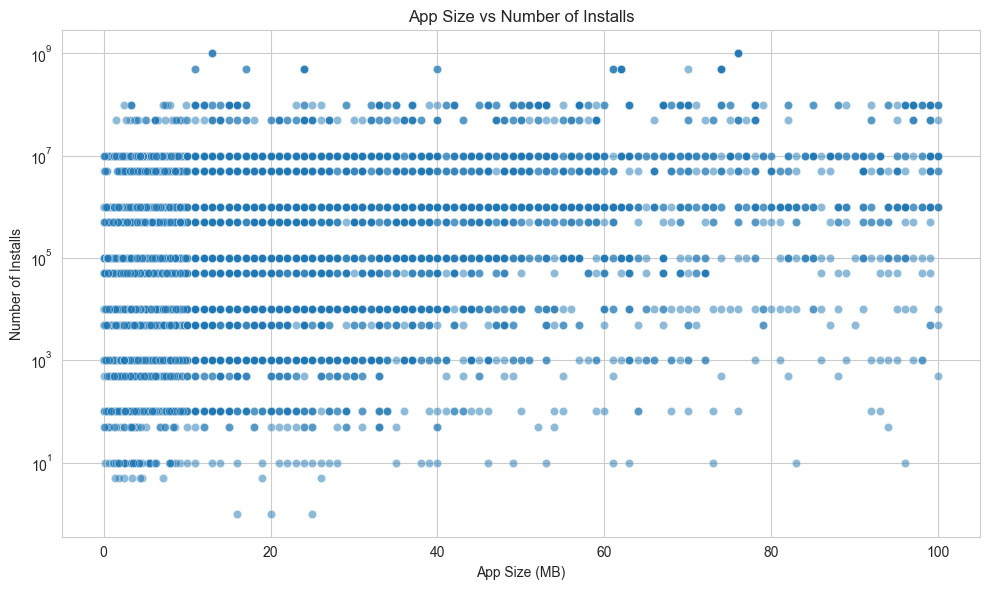

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_data,
    x="Size",
    y="Installs",
    alpha=0.5
)

plt.title("App Size vs Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")
plt.yscale("log")
plt.tight_layout()

plt.savefig("Screenshots/size_vs_installs.png", dpi=300, bbox_inches="tight")
plt.show()

In [35]:
correlation = size_data["Size"].corr(size_data["Installs"])

print("Correlation between App Size and Installs:", round(correlation, 3))

Correlation between App Size and Installs: 0.167


In [36]:
if correlation > 0.5:
    print("There is a strong positive relationship.")
elif correlation > 0:
    print("There is a weak positive relationship.")
elif correlation < -0.5:
    print("There is a strong negative relationship.")
elif correlation < 0:
    print("There is a weak negative relationship.")
else:
    print("There is almost no linear relationship.")

There is a weak positive relationship.


## App Size and Installs Analysis

This analysis studies the relationship between app size and the number of installs.

A scatter plot is used to visualize the relationship between these two variables.

Correlation measures the strength and direction of a linear relationship.

A positive correlation means both variables tend to increase together, while a negative correlation means one tends to decrease as the other increases.

Correlation does not prove that app size causes more or fewer installs.

In [37]:
apps["App_Type"] = np.where(apps["Price"] == 0, "Free", "Paid")

app_type_counts = apps["App_Type"].value_counts()

print("Free and Paid Apps:")
display(app_type_counts)

Free and Paid Apps:


App_Type
Free    8280
Paid     613
Name: count, dtype: int64

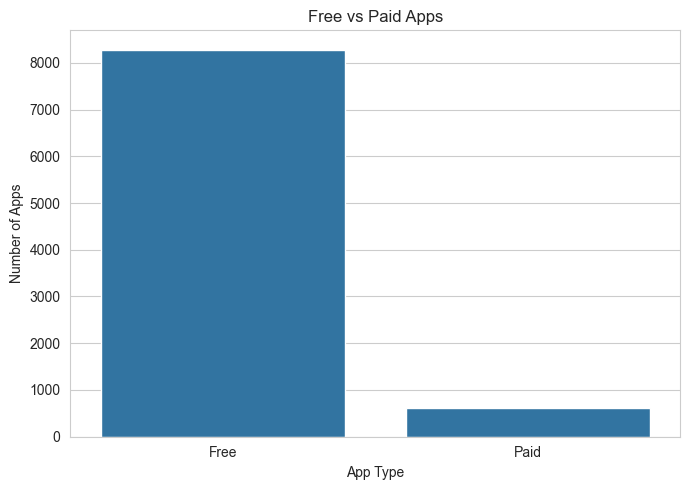

In [38]:
plt.figure(figsize=(7, 5))

sns.countplot(data=apps, x="App_Type")

plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()

plt.savefig("Screenshots/free_vs_paid.png", dpi=300, bbox_inches="tight")
plt.show()

In [39]:
paid_apps = apps[apps["Price"] > 0].copy()

print("Total Paid Apps:", len(paid_apps))
print("\nPaid App Price Statistics:")
display(paid_apps["Price"].describe())

Total Paid Apps: 613

Paid App Price Statistics:


count    613.000000
mean      13.971240
std       60.213108
min        0.990000
25%        1.990000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

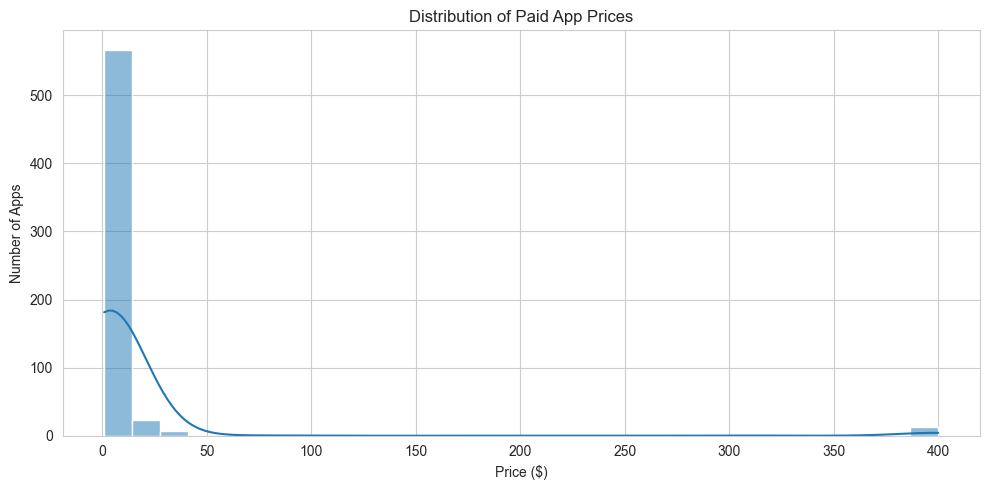

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(paid_apps["Price"], bins=30, kde=True)

plt.title("Distribution of Paid App Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.tight_layout()

plt.savefig("Screenshots/paid_app_prices.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
paid_apps["Estimated_Revenue"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

revenue_by_category = (
    paid_apps.groupby("Category")["Estimated_Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Estimated Revenue by Category:")
display(revenue_by_category.head(10))

Estimated Revenue by Category:


Category
FAMILY             1.857743e+08
LIFESTYLE          5.758394e+07
GAME               4.098684e+07
FINANCE            2.572664e+07
PHOTOGRAPHY        8.941050e+06
MEDICAL            8.371355e+06
PERSONALIZATION    7.786310e+06
TOOLS              5.462910e+06
SPORTS             4.706154e+06
PRODUCTIVITY       4.304452e+06
Name: Estimated_Revenue, dtype: float64

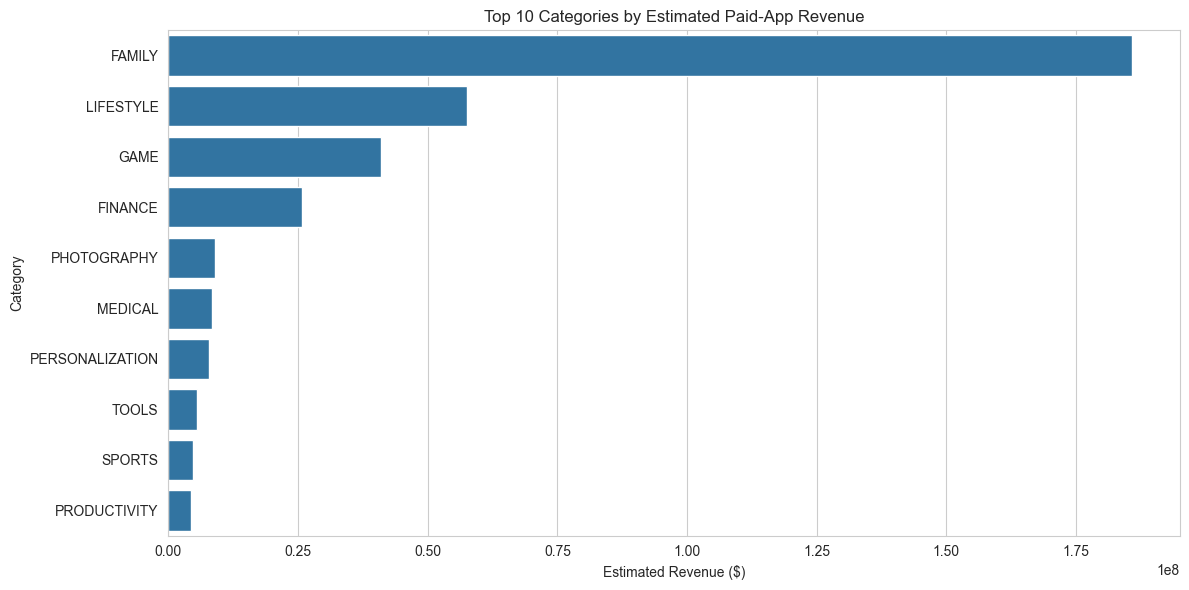

In [42]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=revenue_by_category.head(10).values,
    y=revenue_by_category.head(10).index
)

plt.title("Top 10 Categories by Estimated Paid-App Revenue")
plt.xlabel("Estimated Revenue ($)")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig("Screenshots/revenue_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

## Pricing Analysis

This analysis compares free and paid applications.

The price distribution helps us understand the pricing strategies used by developers.

Estimated revenue is calculated by multiplying app price by the number of installs.

This is only an approximate estimate and does not represent actual developer earnings.

In [43]:
print("Reviews Dataset:")
display(reviews.head(10))

print("\nReview Columns:")
print(reviews.columns.tolist())

Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000
6,10 Best Foods for You,Amazing,Positive,0.60,0.900000
8,10 Best Foods for You,"Looking forward app,",Neutral,0.00,0.000000
9,10 Best Foods for You,It helpful site ! It help foods get !,Neutral,0.00,0.000000
10,10 Best Foods for You,good you.,Positive,0.70,0.600000



Review Columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [44]:
print("Missing Values:")
print(reviews[["App", "Translated_Review"]].isnull().sum())

Missing Values:
App                    0
Translated_Review    987
dtype: int64


In [45]:
reviews = reviews.dropna(subset=["Translated_Review"]).copy()

reviews["Translated_Review"] = (
    reviews["Translated_Review"].astype(str).str.strip()
)

reviews = reviews[reviews["Translated_Review"] != ""]

reviews = reviews.drop_duplicates()

print("Reviews cleaned successfully!")
print("Remaining Reviews:", len(reviews))

Reviews cleaned successfully!
Remaining Reviews: 29692


In [46]:
analyzer = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer initialized successfully!")

VADER Sentiment Analyzer initialized successfully!


In [47]:
reviews["Sentiment_Score"] = reviews["Translated_Review"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

print("Sentiment scores calculated successfully!")

display(
    reviews[["Translated_Review", "Sentiment_Score"]].head(10)
)

Sentiment scores calculated successfully!


,Translated_Review,Sentiment_Score
0,I like eat delicious food. That's I'm cooking ...,0.9531
1,This help eating healthy exercise regular basis,0.6597
3,Works great especially going grocery store,0.6249
4,Best idea us,0.6369
5,Best way,0.6369
6,Amazing,0.5859
8,"Looking forward app,",0.0000
9,It helpful site ! It help foods get !,0.7256
10,good you.,0.4404
11,Useful information The amount spelling errors ...,0.4404


In [48]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews["Sentiment"] = reviews["Sentiment_Score"].apply(
    classify_sentiment
)

print("Sentiment classification completed!")

display(
    reviews[["Translated_Review", "Sentiment_Score", "Sentiment"]].head(10)
)

Sentiment classification completed!


,Translated_Review,Sentiment_Score,Sentiment
0,I like eat delicious food. That's I'm cooking ...,0.9531,Positive
1,This help eating healthy exercise regular basis,0.6597,Positive
3,Works great especially going grocery store,0.6249,Positive
4,Best idea us,0.6369,Positive
5,Best way,0.6369,Positive
6,Amazing,0.5859,Positive
8,"Looking forward app,",0.0000,Neutral
9,It helpful site ! It help foods get !,0.7256,Positive
10,good you.,0.4404,Positive
11,Useful information The amount spelling errors ...,0.4404,Positive


In [49]:
sentiment_counts = reviews["Sentiment"].value_counts()

print("Sentiment Distribution:")
display(sentiment_counts)

Sentiment Distribution:


Sentiment
Positive    20197
Negative     5866
Neutral      3629
Name: count, dtype: int64

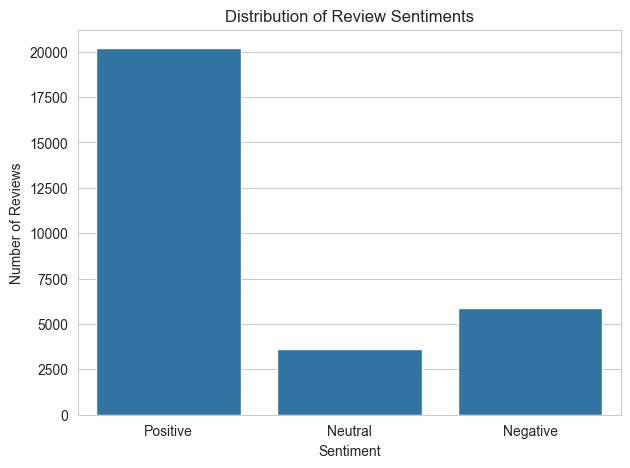

In [50]:
plt.figure(figsize=(7, 5))
sns.countplot(data=reviews, x="Sentiment", order=["Positive", "Neutral", "Negative"])

plt.title("Distribution of Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.savefig("Screenshots/sentiment_distribution.png", bbox_inches="tight")
plt.show()

In [51]:
sentiment_percent = (
    reviews["Sentiment"].value_counts(normalize=True) * 100
).round(2)

display(sentiment_percent)

Sentiment
Positive    68.02
Negative    19.76
Neutral     12.22
Name: proportion, dtype: float64

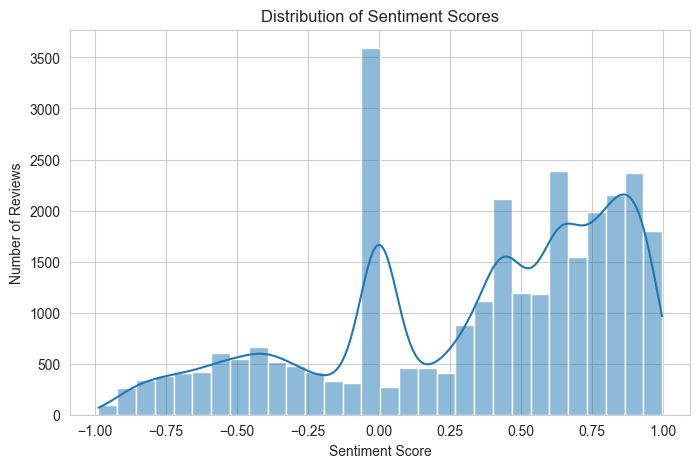

In [52]:
plt.figure(figsize=(8, 5))
sns.histplot(reviews["Sentiment_Score"], bins=30, kde=True)

plt.title("Distribution of Sentiment Scores")
plt.xlabel("Sentiment Score")
plt.ylabel("Number of Reviews")
plt.savefig("Screenshots/sentiment_score_distribution.png", bbox_inches="tight")
plt.show()

In [53]:
reviews_with_category = reviews.merge(
    apps[["App", "Category"]].drop_duplicates(subset=["App"]),
    on="App",
    how="left"
)

print("Reviews without category:", reviews_with_category["Category"].isna().sum())

reviews_with_category = reviews_with_category.dropna(subset=["Category"])

Reviews without category: 1442


In [54]:
sentiment_by_category = pd.crosstab(
    reviews_with_category["Category"],
    reviews_with_category["Sentiment"],
    normalize="index"
) * 100

display(sentiment_by_category.round(2))

Sentiment,Negative,Neutral,Positive
Category,,,
ART_AND_DESIGN,13.28,11.86,74.86
AUTO_AND_VEHICLES,4.95,12.72,82.33
BEAUTY,20.19,19.56,60.25
BOOKS_AND_REFERENCE,16.05,11.51,72.45
BUSINESS,16.89,19.79,63.32
COMICS,2.22,11.11,86.67
COMMUNICATION,25.15,12.87,61.99
DATING,22.26,14.72,63.02
EDUCATION,10.40,10.87,78.73


In [55]:
category_sentiment = (
    reviews_with_category.groupby("Category")["Sentiment_Score"]
    .mean()
    .sort_values(ascending=False)
)

display(category_sentiment.round(3))

Category
COMICS                 0.539
AUTO_AND_VEHICLES      0.518
HEALTH_AND_FITNESS     0.484
EDUCATION              0.475
PARENTING              0.460
EVENTS                 0.448
FOOD_AND_DRINK         0.426
ART_AND_DESIGN         0.425
GAME                   0.392
FAMILY                 0.392
MEDICAL                0.381
BOOKS_AND_REFERENCE    0.378
PRODUCTIVITY           0.366
LIBRARIES_AND_DEMO     0.360
PERSONALIZATION        0.355
PHOTOGRAPHY            0.346
SHOPPING               0.340
LIFESTYLE              0.329
MAPS_AND_NAVIGATION    0.312
SPORTS                 0.306
WEATHER                0.305
FINANCE                0.296
BUSINESS               0.295
TRAVEL_AND_LOCAL       0.285
HOUSE_AND_HOME         0.284
TOOLS                  0.284
DATING                 0.275
COMMUNICATION          0.250
BEAUTY                 0.245
ENTERTAINMENT          0.234
NEWS_AND_MAGAZINES     0.208
VIDEO_PLAYERS          0.185
SOCIAL                 0.170
Name: Sentiment_Score, dtype: floa

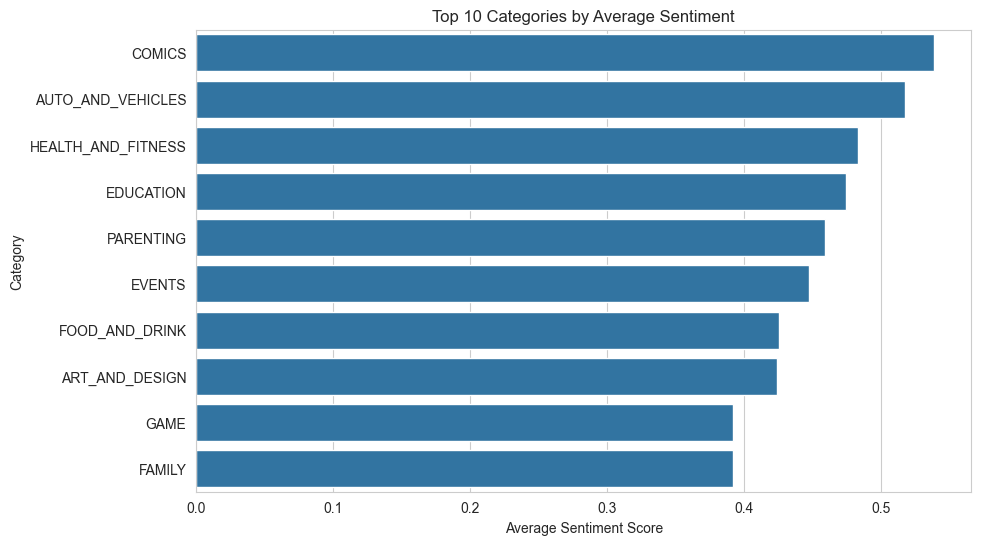

In [56]:
top_sentiment = category_sentiment.head(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top_sentiment, x="Sentiment_Score", y="Category")

plt.title("Top 10 Categories by Average Sentiment")
plt.xlabel("Average Sentiment Score")
plt.ylabel("Category")
plt.savefig("Screenshots/top_10_category_sentiment.png", bbox_inches="tight")
plt.show()

In [57]:
import plotly.express as px

plot_data = size_data.sample(
    n=min(2000, len(size_data)),
    random_state=42
)

fig = px.scatter(
    plot_data,
    x="Size",
    y="Installs",
    color="Category",
    hover_name="App",
    log_y=True,
    title="Interactive App Size vs Installs"
)

fig.show()

fig.write_html("Outputs/interactive_size_vs_installs.html")

In [58]:
apps.to_csv("Outputs/cleaned_apps.csv", index=False)

reviews_with_category.to_csv(
    "Outputs/reviews_with_sentiment.csv",
    index=False
)

sentiment_by_category.to_csv(
    "Outputs/sentiment_by_category.csv"
)

print("All cleaned datasets saved successfully!")

All cleaned datasets saved successfully!


In [59]:
top_category = apps["Category"].value_counts().idxmax()
top_category_count = apps["Category"].value_counts().max()

highest_rated = apps.groupby("Category")["Rating"].mean().idxmax()
highest_rating = apps.groupby("Category")["Rating"].mean().max()

lowest_rated = apps.groupby("Category")["Rating"].mean().idxmin()
lowest_rating = apps.groupby("Category")["Rating"].mean().min()

best_sentiment = category_sentiment.idxmax()
best_sentiment_score = category_sentiment.max()

print("INSIGHT 1: App Categories")
print(f"{top_category} has the highest number of apps ({top_category_count}).")

print("\nINSIGHT 2: App Ratings")
print(f"{highest_rated} has the highest average rating ({highest_rating:.2f}).")
print(f"{lowest_rated} has the lowest average rating ({lowest_rating:.2f}).")

print("\nINSIGHT 3: User Sentiment")
print(f"{best_sentiment} has the highest average sentiment score ({best_sentiment_score:.3f}).")

INSIGHT 1: App Categories
FAMILY has the highest number of apps (1718).

INSIGHT 2: App Ratings
1.9 has the highest average rating (19.00).
DATING has the lowest average rating (3.97).

INSIGHT 3: User Sentiment
COMICS has the highest average sentiment score (0.539).


In [60]:
print("Apps dataset:", apps.shape)
print("Reviews dataset:", reviews_with_category.shape)

print("\nOutput files:")
print(os.listdir("Outputs"))

print("\nScreenshot files:")
print(os.listdir("Screenshots"))

Apps dataset: (8893, 14)
Reviews dataset: (28250, 7)

Output files:
['cleaned_apps.csv', 'interactive_size_vs_installs.html', 'reviews_with_sentiment.csv', 'sentiment_by_category.csv']

Screenshot files:
['average_rating_by_category.png', 'category_distribution.png', 'free_vs_paid.png', 'paid_app_prices.png', 'rating_distribution.png', 'revenue_by_category.png', 'sentiment_distribution.png', 'sentiment_score_distribution.png', 'size_vs_installs.png', 'top_10_categories.png', 'top_10_category_sentiment.png']


## Conclusion

The Google Play Store analysis helped us understand app categories, ratings, installations, pricing, and user opinions.

- Category analysis showed which categories contain the highest number of apps.
- Rating analysis helped identify categories with higher and lower average ratings.
- Size and installation analysis explored the relationship between app size and popularity.
- Pricing analysis compared free and paid applications.
- Sentiment analysis classified user reviews into positive, neutral, and negative opinions.

The project provides useful insights into app market trends and user satisfaction. These findings can help developers understand user preferences and improve their applications.

Note: Sentiment scores are machine-generated estimates, and estimated revenue is only an approximate measure.